# Rice Field Water Level Classifier — 3 Classes (Dry / Medium / High)
**Classes:**
- `0 = Dry`    → water level mean < -1
- `1 = Medium` → -1 <= water level mean <= 5
- `2 = High`   → water level mean > 5

**Input:** Past 14 days of Sentinel-1 + Sentinel-2 satellite features  
**Model:** XGBoost Classifier

In [59]:
import subprocess
subprocess.run(['pip', 'install', 'earthengine-api', 'rasterio', 'xgboost', 
                'scikit-learn', 'pandas', 'numpy'], check=True)


[notice] A new release of pip is available: 23.2.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['pip', 'install', 'earthengine-api', 'rasterio', 'xgboost', 'scikit-learn', 'pandas', 'numpy'], returncode=0)

In [60]:
# ── BLOCK 1: Imports & Config ─────────────────────────────────────────────────
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, f1_score,
                              confusion_matrix, classification_report,
                              ConfusionMatrixDisplay)
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# ── Lookback window ───────────────────────────────────────────────────────────
LOOKBACK = 14            # past 14 days of satellite data → predict today's label

# ── Classification thresholds ─────────────────────────────────────────────────
LOW_THRESHOLD  = -1      # mean < -1        → Dry    (0)
HIGH_THRESHOLD =  5      # mean > 5         → High   (2)
                         # -1 <= mean <= 5  → Medium (1)

# ── XGBoost hyperparameters ───────────────────────────────────────────────────
XGB_PARAMS = dict(
    n_estimators     = 300,
    max_depth        = 6,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    objective        = 'multi:softmax',
    num_class        = 3,
    eval_metric      = 'mlogloss',
    random_state     = 42,
)

# ── Train/test split ──────────────────────────────────────────────────────────
TRAIN_FRAC          = 0.80
TEST_FIELD_YEARS    = ['5_2022', '14_2023', '55_2021', '11_2024',
                       '7_2021', '8_2022', '2_2024', '9_2023']
EXCLUDE_FIELD_YEARS = ['55_2022', '66_2022', '77_2022', '88_2022']

print('Config ready.')

Config ready.


In [61]:
# ── BLOCK 2: File Paths & Sensor Config ───────────────────────────────────────
NDVI_FILES = [
    "final/sentinel2_2021_full - final - sentinel2_2021_full - Sheet1 (1).csv.csv",
    "final/sentinel2_2022_full - final - sentinel2_2022_full - Sheet1 (1).csv.csv",
    "final/sentinel2_2023_full - final - sentinel2_2023_full - Sheet1 (1).csv.csv",
    "final/pls_sentinel2_2024_full - final - sentinel2_2024_full - Sheet1 (1).csv.csv",
]
WL_FILES = [
    'final/all_daily_2021_averages_col22 (1).csv',
    'final/all_daily_averages_2022_col22.csv',
    'final/all_daily_averages_2023_col22.csv',
    'final/all_daily_averages_2024_final_col22.csv',
]
S1_FILES = [
    'final/2021_sentinel_1 - Sheet1.csv',
    'final/2022_sentinel_1 - Sheet1.csv',
    'final/2023_sentinel1 - Sheet1 (1).csv',
    'final/2024_sentinel_1 - Sheet1.csv',
]

# ── Column name mappings ───────────────────────────────────────────────────────
NDVI_COLS = {'field':'field', 'date':'date'}
WL_COLS   = {'field':'runkle', 'date':'date', 'mean':'daily_mean',
             'min':'daily_min', 'max':'daily_max', 'std':'daily_std_dev'}
S1_COLS   = {'field':'field', 'date':'date', 'vv':'VV', 'vh':'VH',
             'vv_vh_ratio_db':'VV_VH_ratio_db',
             'vv_vh_ratio_lin':'VV_VH_ratio_lin', 'waterlike':'waterlike'}

# ── Choose which sensors feed the model ───────────────────────────────────────
SENSOR_MODE = 'both'    # options: 'both' | 'sentinel1' | 'sentinel2'

S2_COLS_FEAT = ['b2','b3','b4','b5','b6','b7','b8','b8a','b11','b12',
                'ndvi','ndwi','solar_zenith','solar_azimuth',
                'view_zenith_b4','view_azimuth_b4',
                'view_zenith_b8','view_azimuth_b8']
S1_COLS_FEAT = ['vv','vh','vv_vh_ratio_db','vv_vh_ratio_lin','waterlike']

if SENSOR_MODE == 'both':
    INPUT_COLS = S2_COLS_FEAT + S1_COLS_FEAT
elif SENSOR_MODE == 'sentinel1':
    INPUT_COLS = S1_COLS_FEAT
elif SENSOR_MODE == 'sentinel2':
    INPUT_COLS = S2_COLS_FEAT

N_INPUT_FEATURES = len(INPUT_COLS)
print(f'Sensor mode      : {SENSOR_MODE}')
print(f'N input features : {N_INPUT_FEATURES}')
print(f'Flat window size : {LOOKBACK} x {N_INPUT_FEATURES} = {LOOKBACK * N_INPUT_FEATURES} features per sample')

Sensor mode      : sentinel2
N input features : 18
Flat window size : 14 x 18 = 252 features per sample


In [62]:
# ── BLOCK 3: Loading Functions ────────────────────────────────────────────────

def find_col(df, keyword):
    """Return the first column whose name contains keyword (case-insensitive)."""
    kw = keyword.lower()
    matches = [c for c in df.columns if kw in c.lower()]
    if not matches:
        raise ValueError(f"No column matching '{keyword}' found. Available: {list(df.columns)}")
    return matches[0]


def load_ndvi(path):
    df = pd.read_csv(path)
    df = df.rename(columns={
        find_col(df, 'field'): 'field',
        find_col(df, 'date') : 'date',
    })
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)

    col_lower = {c.lower(): c for c in df.columns}
    all_bands = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12','NDVI','NDWI',
                 'solar_zenith','solar_azimuth',
                 'view_zenith_B4','view_azimuth_B4','view_zenith_B8','view_azimuth_B8']
    band_rename = {}
    for band in all_bands:
        if band.lower() in col_lower:
            band_rename[col_lower[band.lower()]] = band.lower()
    df = df.rename(columns=band_rename)

    s2_cols = [b.lower() for b in all_bands if b.lower() in df.columns]
    for b in s2_cols:
        df[b] = pd.to_numeric(df[b], errors='coerce')
    return df[['field', 'date'] + s2_cols]


def load_waterlevel(path):
    df = pd.read_csv(path)
    col_map = {}
    for final_name, search_term in WL_COLS.items():
        actual_name = find_col(df, search_term)
        col_map[actual_name] = final_name
    df = df.rename(columns=col_map)
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)
    for c in ['mean', 'min', 'max', 'std']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df[['field', 'date', 'mean', 'min', 'max', 'std']]


def load_sentinel1(path):
    df = pd.read_csv(path)
    col_map = {}
    for final_name, search_term in S1_COLS.items():
        actual_name = find_col(df, search_term)
        col_map[actual_name] = final_name
    df = df.rename(columns=col_map)
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)
    for c in ['vv', 'vh', 'vv_vh_ratio_db', 'vv_vh_ratio_lin', 'waterlike']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df[['field', 'date', 'vv', 'vh', 'vv_vh_ratio_db', 'vv_vh_ratio_lin', 'waterlike']]


print('Loading functions defined.')

Loading functions defined.


In [63]:
# ── BLOCK 3.5: Merge Subfields ────────────────────────────────────────────────
# Averages field 40+400 → field 4, and field 140+1400 → field 14

def merge_subfields(df):
    numeric_cols = [c for c in df.columns if c not in ('field', 'date', 'name', 'field_year')]

    pairs = [
        (40,  400,  4),
        (140, 1400, 14),
    ]

    parts = []
    for fA, fB, f_new in pairs:
        has_A = fA in df['field'].values
        has_B = fB in df['field'].values

        if not has_A and not has_B:
            continue

        rows_A = df[df['field'] == fA]
        rows_B = df[df['field'] == fB]

        if has_A and has_B:
            combined = pd.concat([rows_A, rows_B])
            merged   = combined.groupby('date', as_index=False)[numeric_cols].mean()
        elif has_A:
            merged = rows_A.copy()
        else:
            merged = rows_B.copy()

        merged['field'] = f_new
        parts.append(merged)

    fields_to_remove = {40, 400, 140, 1400}
    df_kept = df[~df['field'].isin(fields_to_remove)].copy()

    if parts:
        df_out = pd.concat([df_kept] + parts, ignore_index=True)
    else:
        df_out = df_kept

    return df_out.sort_values(['field', 'date']).reset_index(drop=True)


print('merge_subfields defined.')

merge_subfields defined.


In [64]:
# ── BLOCK 4: Load & Merge Data ────────────────────────────────────────────────

# ── Load Sentinel-2 (NDVI) files ──────────────────────────────────────────────
ndvi_parts = []
for path in NDVI_FILES:
    try:
        df = load_ndvi(path)
        df['field_year'] = df['field'].astype(int).astype(str) + '_' + df['date'].dt.year.astype(str)
        ndvi_parts.append(df)
        print(f'✓ S2  loaded: {path}  ({len(df)} rows)')
    except Exception as e:
        print(f'✗ S2  failed: {path}  ERROR: {e}')

ndvi_df = pd.concat(ndvi_parts).reset_index(drop=True)

# ── Load Water Level files ────────────────────────────────────────────────────
wl_parts = []
for path in WL_FILES:
    try:
        df = load_waterlevel(path)
        df['field_year'] = df['field'].astype(int).astype(str) + '_' + df['date'].dt.year.astype(str)
        wl_parts.append(df)
        print(f'✓ WL  loaded: {path}  ({len(df)} rows)')
    except Exception as e:
        print(f'✗ WL  failed: {path}  ERROR: {e}')

wl_df = pd.concat(wl_parts).reset_index(drop=True)

# ── Load Sentinel-1 files ─────────────────────────────────────────────────────
s1_parts = []
for path in S1_FILES:
    try:
        df = load_sentinel1(path)
        df['field_year'] = df['field'].astype(int).astype(str) + '_' + df['date'].dt.year.astype(str)
        s1_parts.append(df)
        print(f'✓ S1  loaded: {path}  ({len(df)} rows)')
    except Exception as e:
        print(f'✗ S1  failed: {path}  ERROR: {e}')

s1_df = pd.concat(s1_parts).reset_index(drop=True)

# ── Merge subfields (40+400→4, 140+1400→14) ───────────────────────────────────
ndvi_df = merge_subfields(ndvi_df)
wl_df   = merge_subfields(wl_df)
s1_df   = merge_subfields(s1_df)

# ── Re-tag field_year after merge (field numbers may have changed) ─────────────
for _df in [ndvi_df, wl_df, s1_df]:
    _df['field_year'] = _df['field'].astype(int).astype(str) + '_' + _df['date'].dt.year.astype(str)

# ── Find field-years present in ALL THREE sources ─────────────────────────────
common_keys = sorted(
    set(ndvi_df['field_year'].unique())
    & set(wl_df['field_year'].unique())
    & set(s1_df['field_year'].unique())
)

print(f'\nCommon field-years across all 3 sources: {len(common_keys)}')
print(common_keys)

✓ S2  loaded: final/sentinel2_2021_full - final - sentinel2_2021_full - Sheet1 (1).csv.csv  (360 rows)
✓ S2  loaded: final/sentinel2_2022_full - final - sentinel2_2022_full - Sheet1 (1).csv.csv  (397 rows)
✓ S2  loaded: final/sentinel2_2023_full - final - sentinel2_2023_full - Sheet1 (1).csv.csv  (471 rows)
✓ S2  loaded: final/pls_sentinel2_2024_full - final - sentinel2_2024_full - Sheet1 (1).csv.csv  (368 rows)
✓ WL  loaded: final/all_daily_2021_averages_col22 (1).csv  (1733 rows)
✓ WL  loaded: final/all_daily_averages_2022_col22.csv  (2171 rows)
✓ WL  loaded: final/all_daily_averages_2023_col22.csv  (1922 rows)
✓ WL  loaded: final/all_daily_averages_2024_final_col22.csv  (1423 rows)
✓ S1  loaded: final/2021_sentinel_1 - Sheet1.csv  (320 rows)
✓ S1  loaded: final/2022_sentinel_1 - Sheet1.csv  (214 rows)
✓ S1  loaded: final/2023_sentinel1 - Sheet1 (1).csv  (231 rows)
✓ S1  loaded: final/2024_sentinel_1 - Sheet1.csv  (260 rows)

Common field-years across all 3 sources: 61
['11_2021', '1

In [65]:
# ── BLOCK 5: Build field_data Dictionary ──────────────────────────────────────

field_data = {}

for key in common_keys:

    # ── Skip excluded field-years ─────────────────────────────────────────────
    if key in EXCLUDE_FIELD_YEARS:
        print(f'  {key}: excluded — skipping')
        continue

    # ── Pull each source for this field-year, select only needed columns ───────
    nd = ndvi_df[ndvi_df['field_year'] == key][['date'] + S2_COLS_FEAT].copy()
    s1 = s1_df  [s1_df  ['field_year'] == key][['date'] + S1_COLS_FEAT].copy()
    wl = wl_df  [wl_df  ['field_year'] == key][['date', 'mean', 'min', 'max', 'std']].copy()



    # ── Filter to July end only ────────────────────────────────────────────────
    nd = nd[nd['date'].dt.month <= 7]
    s1 = s1[s1['date'].dt.month <= 7]
    wl = wl[wl['date'].dt.month <= 7]

    # ── Average duplicate dates (same field observed twice in one day) ─────────
    nd = nd.groupby('date')[S2_COLS_FEAT].mean()
    s1 = s1.groupby('date')[S1_COLS_FEAT].mean()
    wl = wl.groupby('date')[['mean', 'min', 'max', 'std']].mean()

    # ── Build complete daily calendar spanning all three sources ───────────────
    start     = min(wl.index.min(), nd.index.min(), s1.index.min())
    end       = max(wl.index.max(), nd.index.max(), s1.index.max())
    daily_idx = pd.date_range(start, end, freq='D')

    # ── Reindex onto daily grid then interpolate satellite gaps ────────────────
    nd_daily = nd.reindex(daily_idx).interpolate(method='time').ffill().bfill()
    s1_daily = s1.reindex(daily_idx).interpolate(method='time').ffill().bfill()

    # ── Water level: reindex only, no interpolation (don't fabricate labels) ───
    wl_daily = wl[['mean', 'min', 'max', 'std']].reindex(daily_idx)

    # ── Combine into one dataframe ─────────────────────────────────────────────
    df = pd.concat([wl_daily, nd_daily, s1_daily], axis=1)

    # ── Drop rows where water level is missing (can't make a label) ────────────
    df = df.dropna(subset=['mean'])

    # ── Skip if not enough days for even one window ────────────────────────────
    if len(df) < LOOKBACK + 1:
        print(f'  {key}: only {len(df)} days — not enough, skipping')
        continue

    field_data[key] = df
    print(f'  {key}: {len(df)} days ready')

print(f'\nTotal field-years ready: {len(field_data)}')

  11_2021: 88 days ready
  11_2022: 81 days ready
  11_2023: 68 days ready
  11_2024: 91 days ready
  12_2021: 95 days ready
  12_2022: 73 days ready
  12_2023: 77 days ready
  12_2024: 73 days ready
  13_2021: 93 days ready
  13_2022: 61 days ready
  13_2023: 70 days ready
  14_2022: 89 days ready
  14_2023: 110 days ready
  14_2024: 106 days ready
  15_2021: 80 days ready
  15_2022: 80 days ready
  15_2023: 88 days ready
  15_2024: 83 days ready
  17_2021: 65 days ready
  17_2022: 34 days ready
  17_2023: 57 days ready
  17_2024: 52 days ready
  18_2021: 58 days ready
  18_2022: 47 days ready
  18_2023: 67 days ready
  18_2024: 79 days ready
  19_2021: 81 days ready
  19_2022: 82 days ready
  1_2024: 92 days ready
  2_2021: 95 days ready
  2_2022: 81 days ready
  2_2023: 77 days ready
  2_2024: 46 days ready
  3_2021: 80 days ready
  3_2022: 42 days ready
  3_2023: 70 days ready
  4_2022: 89 days ready
  4_2023: 104 days ready
  4_2024: 107 days ready
  55_2021: 59 days ready
  55_20

In [66]:
# ── BLOCK 6: Windowing + Label Creation ───────────────────────────────────────

def get_label(value):
    """
    Converts water level mean into a 3-class label:
      0 = Dry    → mean < -1
      1 = Medium → -1 <= mean <= 5
      2 = High   → mean > 5
    """
    #if value < LOW_THRESHOLD:
    #    return 0   # Dry
    #elif value <= HIGH_THRESHOLD:
    #    return 1   # Medium
    #else:
    #    return 2   # High
    
    if value < 0:
        return 0
    else:
        return 1

    #if value < -1
        return 0
    #elif value <= 2
        return 1
    #elif valye <=4
        #return 2
    #else:
        #return 3


def make_windows_flat(df, lookback):
    """
    For each day t, take the past `lookback` days of satellite features
    and label day t based on water level threshold.

    Input  shape: (T, n_features)
    Output shape: (T - lookback, lookback * n_features)  ← flattened for XGBoost
    Labels shape: (T - lookback,)
    """
    X_raw = df[INPUT_COLS].values.astype(np.float32)   # satellite features
    y_raw = df['mean'].values                           # water level

    X_windows, y_labels = [], []

    for i in range(lookback, len(df)):
        # past 14 days of satellite data → flatten into one row
        window = X_raw[i - lookback : i]               # shape: (14, n_features)
        X_windows.append(window.flatten())              # shape: (14 * n_features,)

        # label for day i
        y_labels.append(get_label(y_raw[i]))

    return np.array(X_windows), np.array(y_labels)


# ── Apply to all field-years ───────────────────────────────────────────────────
all_X, all_y, all_keys = [], [], []

for key, df in field_data.items():
    X, y = make_windows_flat(df, LOOKBACK)
    all_X.append(X)
    all_y.append(y)
    all_keys.extend([key] * len(y))
    print(f'  {key}: {len(y)} windows  |  dry={( y==0).sum()}  medium={(y==1).sum()}  high={(y==2).sum()}')

all_X    = np.concatenate(all_X,    axis=0)
all_y    = np.concatenate(all_y,    axis=0)
all_keys = np.array(all_keys)

print(f'\nTotal windows  : {len(all_X)}')
print(f'Total dry   (0): {(all_y==0).sum()}')
print(f'Total medium(1): {(all_y==1).sum()}')
print(f'Total high  (2): {(all_y==2).sum()}')
print(f'Feature size   : {all_X.shape[1]}  ({LOOKBACK} days x {N_INPUT_FEATURES} features)')

  11_2021: 74 windows  |  dry=51  medium=11  high=12
  11_2022: 67 windows  |  dry=0  medium=11  high=56
  11_2023: 54 windows  |  dry=0  medium=17  high=37
  11_2024: 77 windows  |  dry=0  medium=4  high=73
  12_2021: 81 windows  |  dry=22  medium=16  high=43
  12_2022: 59 windows  |  dry=0  medium=13  high=46
  12_2023: 63 windows  |  dry=1  medium=8  high=54
  12_2024: 59 windows  |  dry=9  medium=7  high=43
  13_2021: 79 windows  |  dry=42  medium=7  high=30
  13_2022: 47 windows  |  dry=5  medium=18  high=24
  13_2023: 56 windows  |  dry=14  medium=4  high=38
  14_2022: 75 windows  |  dry=0  medium=21  high=54
  14_2023: 96 windows  |  dry=59  medium=19  high=18
  14_2024: 92 windows  |  dry=29  medium=27  high=36
  15_2021: 66 windows  |  dry=19  medium=18  high=29
  15_2022: 66 windows  |  dry=0  medium=9  high=57
  15_2023: 74 windows  |  dry=8  medium=0  high=66
  15_2024: 69 windows  |  dry=0  medium=4  high=65
  17_2021: 51 windows  |  dry=12  medium=13  high=26
  17_2022: 2

In [67]:
# ── BLOCK 7: Train / Validation / Test Split ──────────────────────────────────

# ── Separate held-out test field-years first ──────────────────────────────────
test_mask  = np.isin(all_keys, TEST_FIELD_YEARS)
train_mask = ~test_mask

X_test  = all_X[test_mask]
y_test  = all_y[test_mask]

X_trainval    = all_X[train_mask]
y_trainval    = all_y[train_mask]
keys_trainval = all_keys[train_mask]

# ── Split remaining field-years into train and validation ─────────────────────
remaining_keys = [k for k in field_data.keys() if k not in TEST_FIELD_YEARS]

n_train    = int(len(remaining_keys) * TRAIN_FRAC)
train_keys = remaining_keys[:n_train]
val_keys   = remaining_keys[n_train:]

train_mask_tv = np.isin(keys_trainval, train_keys)
val_mask_tv   = np.isin(keys_trainval, val_keys)

X_train = X_trainval[train_mask_tv]
y_train = y_trainval[train_mask_tv]

X_val   = X_trainval[val_mask_tv]
y_val   = y_trainval[val_mask_tv]

# ── Scale features ────────────────────────────────────────────────────────────
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit only on train
X_val   = scaler.transform(X_val)         # apply same scale to val
X_test  = scaler.transform(X_test)        # apply same scale to test

print(f'Train : {X_train.shape}  |  dry={(y_train==0).sum()}  medium={(y_train==1).sum()}  high={(y_train==2).sum()}')
print(f'Val   : {X_val.shape}    |  dry={(y_val==0).sum()}  medium={(y_val==1).sum()}  high={(y_val==2).sum()}')
print(f'Test  : {X_test.shape}   |  dry={(y_test==0).sum()}  medium={(y_test==1).sum()}  high={(y_test==2).sum()}')
print(f'\nTrain field-years : {train_keys}')
print(f'Val   field-years : {val_keys}')
print(f'Test  field-years : {TEST_FIELD_YEARS}')

Train : (2456, 252)  |  dry=381  medium=362  high=1713
Val   : (515, 252)    |  dry=67  medium=100  high=348
Test  : (461, 252)   |  dry=115  medium=132  high=214

Train field-years : ['11_2021', '11_2022', '11_2023', '12_2021', '12_2022', '12_2023', '12_2024', '13_2021', '13_2022', '13_2023', '14_2022', '14_2024', '15_2021', '15_2022', '15_2023', '15_2024', '17_2021', '17_2022', '17_2023', '17_2024', '18_2021', '18_2022', '18_2023', '18_2024', '19_2021', '19_2022', '1_2024', '2_2021', '2_2022', '2_2023', '3_2021', '3_2022', '3_2023', '4_2022', '4_2023', '4_2024', '55_2023', '5_2021', '5_2023']
Val   field-years : ['5_2024', '66_2021', '66_2023', '7_2022', '7_2023', '7_2024', '8_2023', '8_2024', '9_2021', '9_2022']
Test  field-years : ['5_2022', '14_2023', '55_2021', '11_2024', '7_2021', '8_2022', '2_2024', '9_2023']


In [68]:
# ── BLOCK 8: Train XGBoost Classifier ────────────────────────────────────────

model = XGBClassifier(**XGB_PARAMS)

# ── Train with validation monitoring ─────────────────────────────────────────
model.fit(
    X_train, y_train,
    eval_set = [(X_train, y_train), (X_val, y_val)],
    verbose  = 25,    # print progress every 25 trees
)

print('\nTraining complete!')

[0]	validation_0-mlogloss:0.79298	validation_1-mlogloss:0.84658
[25]	validation_0-mlogloss:0.42109	validation_1-mlogloss:0.70132
[50]	validation_0-mlogloss:0.27182	validation_1-mlogloss:0.67563
[75]	validation_0-mlogloss:0.19840	validation_1-mlogloss:0.68203
[100]	validation_0-mlogloss:0.15031	validation_1-mlogloss:0.70005
[125]	validation_0-mlogloss:0.11962	validation_1-mlogloss:0.72082
[150]	validation_0-mlogloss:0.09582	validation_1-mlogloss:0.74251
[175]	validation_0-mlogloss:0.07801	validation_1-mlogloss:0.77182
[200]	validation_0-mlogloss:0.06513	validation_1-mlogloss:0.79190
[225]	validation_0-mlogloss:0.05525	validation_1-mlogloss:0.81150
[250]	validation_0-mlogloss:0.04725	validation_1-mlogloss:0.83348
[275]	validation_0-mlogloss:0.04135	validation_1-mlogloss:0.85828
[299]	validation_0-mlogloss:0.03662	validation_1-mlogloss:0.87804

Training complete!



── TRAIN ────────────────────────────────
Accuracy : 0.9967
F1 Score : 0.9967  (weighted)

Classification Report:
              precision    recall  f1-score   support

     Dry (0)       0.98      1.00      0.99       381
  Medium (1)       1.00      0.98      0.99       362
    High (2)       1.00      1.00      1.00      1713

    accuracy                           1.00      2456
   macro avg       0.99      0.99      0.99      2456
weighted avg       1.00      1.00      1.00      2456



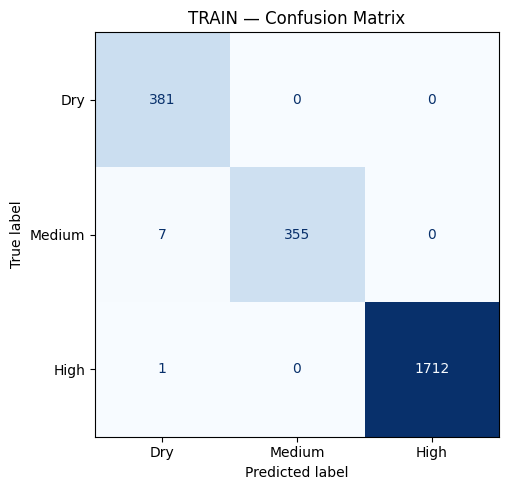


── VAL ────────────────────────────────
Accuracy : 0.7379
F1 Score : 0.6732  (weighted)

Classification Report:
              precision    recall  f1-score   support

     Dry (0)       0.71      0.51      0.59        67
  Medium (1)       0.33      0.06      0.10       100
    High (2)       0.76      0.98      0.85       348

    accuracy                           0.74       515
   macro avg       0.60      0.51      0.52       515
weighted avg       0.67      0.74      0.67       515



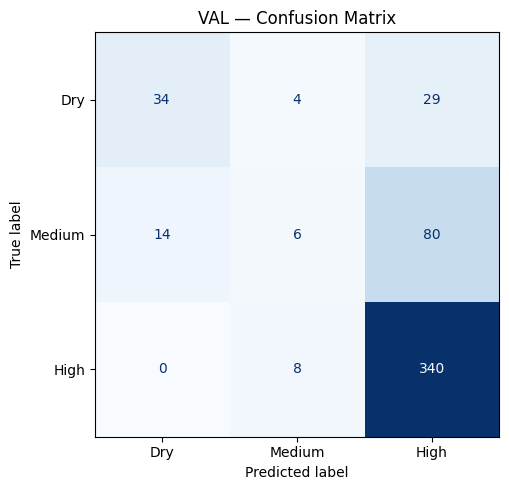


── TEST ────────────────────────────────
Accuracy : 0.5900
F1 Score : 0.5159  (weighted)

Classification Report:
              precision    recall  f1-score   support

     Dry (0)       0.85      0.46      0.60       115
  Medium (1)       0.61      0.08      0.15       132
    High (2)       0.55      0.97      0.70       214

    accuracy                           0.59       461
   macro avg       0.67      0.51      0.48       461
weighted avg       0.64      0.59      0.52       461



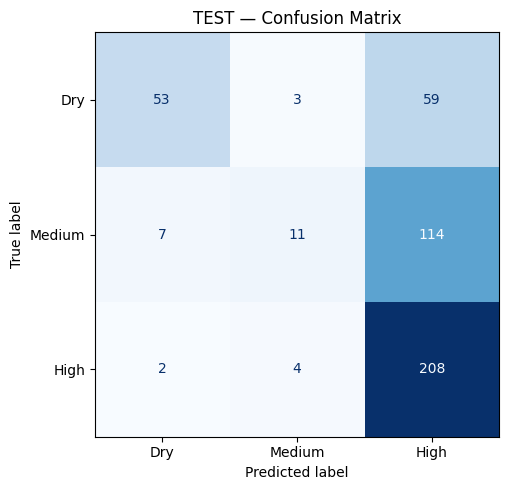

In [69]:
# ── BLOCK 9: Evaluation & Results ─────────────────────────────────────────────

CLASS_NAMES = ['Dry (0)', 'Medium (1)', 'High (2)']

def evaluate(name, X, y):
    preds = model.predict(X)
    acc   = accuracy_score(y, preds)
    f1    = f1_score(y, preds, average='weighted')

    print(f'\n── {name} ────────────────────────────────')
    print(f'Accuracy : {acc:.4f}')
    print(f'F1 Score : {f1:.4f}  (weighted)')
    print(f'\nClassification Report:')
    print(classification_report(y, preds, target_names=CLASS_NAMES))

    # ── Confusion Matrix ──────────────────────────────────────────────────────
    cm   = confusion_matrix(y, preds)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=['Dry', 'Medium', 'High'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name} — Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return preds


# ── Run on all three splits ───────────────────────────────────────────────────
preds_train = evaluate('TRAIN', X_train, y_train)
preds_val   = evaluate('VAL',   X_val,   y_val)
preds_test  = evaluate('TEST',  X_test,  y_test)

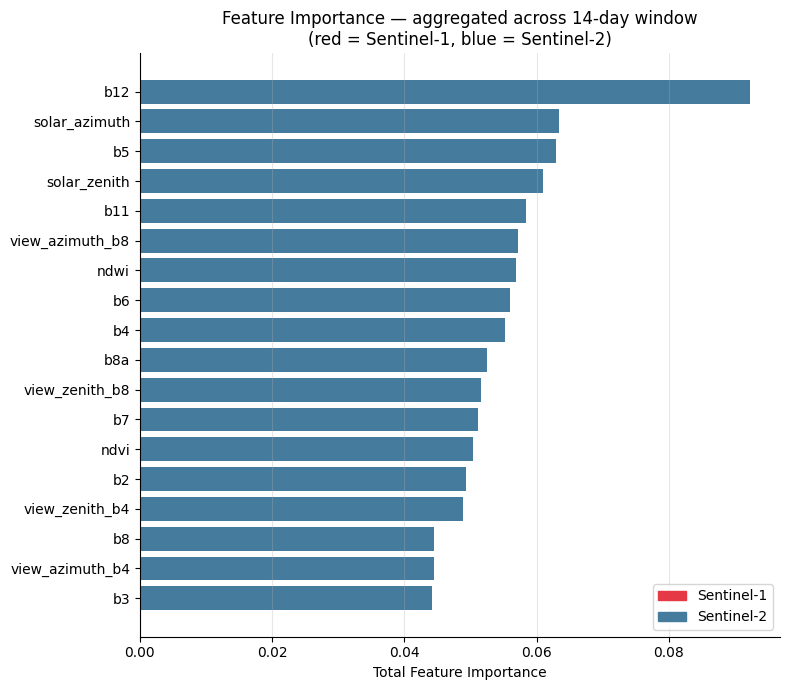


Top 5 most important features:
      feature  importance
          b12    0.092201
solar_azimuth    0.063368
           b5    0.063007
 solar_zenith    0.060964
          b11    0.058427


In [70]:
# ── BLOCK 10: Feature Importance ─────────────────────────────────────────────

# ── Feature names: day_1_vv, day_1_vh, ..., day_14_ndvi etc. ─────────────────
feature_names = [f'day{d+1}_{col}' for d in range(LOOKBACK) for col in INPUT_COLS]

importances = model.feature_importances_

# ── Aggregate importance per feature (sum across all 14 days) ─────────────────
agg_importance = {col: 0.0 for col in INPUT_COLS}
for i, name in enumerate(feature_names):
    col = name.split('_', 1)[1]   # strip 'dayN_' prefix
    agg_importance[col] += importances[i]

imp_df = pd.DataFrame({
    'feature'   : list(agg_importance.keys()),
    'importance': list(agg_importance.values()),
}).sort_values('importance', ascending=True)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))
colors  = ['#e63946' if f in S1_COLS_FEAT else '#457b9d' for f in imp_df['feature']]
ax.barh(imp_df['feature'], imp_df['importance'], color=colors)
ax.set_xlabel('Total Feature Importance')
ax.set_title('Feature Importance — aggregated across 14-day window\n(red = Sentinel-1, blue = Sentinel-2)')

from matplotlib.patches import Patch
legend = [Patch(color='#e63946', label='Sentinel-1'),
          Patch(color='#457b9d', label='Sentinel-2')]
ax.legend(handles=legend)
ax.grid(True, alpha=0.3, axis='x')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print('\nTop 5 most important features:')
print(imp_df.tail(5)[['feature','importance']].iloc[::-1].to_string(index=False))

In [71]:
# ── BLOCK 5.5: Pearson Correlation — NDVI vs Mean Water Level ─────────────────
from scipy.stats import pearsonr

results = []

for key, df in field_data.items():

    # ── Drop rows where either NDVI or water level is NaN ─────────────────────
    valid = df[['ndvi', 'mean']].dropna()

    if len(valid) < 10:
        print(f'  {key}: not enough valid rows — skipping')
        continue

    r, p_value = pearsonr(valid['ndvi'], valid['mean'])

    results.append({
        'field_year' : key,
        'pearson_r'  : round(r, 4),
        'p_value'    : round(p_value, 4),
        'n_days'     : len(valid),
        'significant': 'Yes' if p_value < 0.05 else 'No'
    })

    print(f'  {key}: r = {r:.4f}  |  p = {p_value:.4f}  |  n = {len(valid)}')

# ── Summary table ──────────────────────────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('pearson_r', ascending=False)

print('\n── Summary ───────────────────────────────────────────────')
print(results_df.to_string(index=False))
print(f'\nMean r across all field-years : {results_df["pearson_r"].mean():.4f}')
print(f'Significant (p<0.05)          : {results_df["significant"].value_counts()["Yes"]} / {len(results_df)}')

  11_2021: r = 0.4229  |  p = 0.0000  |  n = 88
  11_2022: r = 0.8514  |  p = 0.0000  |  n = 81
  11_2023: r = 0.5257  |  p = 0.0000  |  n = 68
  11_2024: r = 0.6584  |  p = 0.0000  |  n = 91
  12_2021: r = 0.9148  |  p = 0.0000  |  n = 95
  12_2022: r = 0.8706  |  p = 0.0000  |  n = 73
  12_2023: r = 0.5856  |  p = 0.0000  |  n = 77
  12_2024: r = 0.3630  |  p = 0.0016  |  n = 73
  13_2021: r = 0.7774  |  p = 0.0000  |  n = 93
  13_2022: r = 0.6688  |  p = 0.0000  |  n = 61
  13_2023: r = 0.9395  |  p = 0.0000  |  n = 70
  14_2022: r = 0.4358  |  p = 0.0000  |  n = 89
  14_2023: r = 0.2843  |  p = 0.0026  |  n = 110
  14_2024: r = 0.3750  |  p = 0.0001  |  n = 106
  15_2021: r = 0.4861  |  p = 0.0000  |  n = 80
  15_2022: r = 0.8735  |  p = 0.0000  |  n = 80
  15_2023: r = 0.7642  |  p = 0.0000  |  n = 88
  15_2024: r = 0.5987  |  p = 0.0000  |  n = 83
  17_2021: r = 0.8252  |  p = 0.0000  |  n = 65
  17_2022: r = 0.6249  |  p = 0.0001  |  n = 34
  17_2023: r = 0.6577  |  p = 0.0000  

In [72]:
# ── BLOCK 6.5: Last Real Acquisition Before Each Prediction Date ───────────────
def get_last_acquisitions(key, pred_dates):
    """
    For each prediction date, find the closest real (non-interpolated)
    Sentinel-1 and Sentinel-2 acquisition before that date.
    """

    # ── Pull raw (pre-interpolation) dates for this field-year ────────────────
    s2_real = ndvi_df[ndvi_df['field_year'] == key]['date'].dt.normalize().unique()
    s1_real = s1_df  [s1_df  ['field_year'] == key]['date'].dt.normalize().unique()

    # ── Filter to July end ─────────────────────────────────────────────────────
    s2_real = pd.DatetimeIndex(s2_real)
    s1_real = pd.DatetimeIndex(s1_real)
    s2_real = s2_real[s2_real.month <= 7]
    s1_real = s1_real[s1_real.month <= 7]

    rows = []
    for pred_date in pred_dates:

        # ── Last S2 acquisition on or before pred_date ─────────────────────────
        s2_before = s2_real[s2_real <= pred_date]
        last_s2   = s2_before.max() if len(s2_before) > 0 else pd.NaT
        days_s2   = (pred_date - last_s2).days if pd.notna(last_s2) else None

        # ── Last S1 acquisition on or before pred_date ─────────────────────────
        s1_before = s1_real[s1_real <= pred_date]
        last_s1   = s1_before.max() if len(s1_before) > 0 else pd.NaT
        days_s1   = (pred_date - last_s1).days if pd.notna(last_s1) else None

        rows.append({
            'field_year'  : key,
            'pred_date'   : pred_date,
            'last_s2_date': last_s2,
            'days_since_s2': days_s2,
            'last_s1_date': last_s1,
            'days_since_s1': days_s1,
        })

    return pd.DataFrame(rows)


# ── Apply to all field-years ───────────────────────────────────────────────────
acq_records = []

for key, df in field_data.items():
    # prediction dates = all dates after the first LOOKBACK days
    pred_dates = df.index[LOOKBACK:]
    acq_df     = get_last_acquisitions(key, pred_dates)
    acq_records.append(acq_df)

acq_summary = pd.concat(acq_records, ignore_index=True)

print(acq_summary.head(10).to_string(index=False))

print(f'\n── Summary ───────────────────────────────────────────────────')
print(f'Mean days since last S2 : {acq_summary["days_since_s2"].mean():.1f}')
print(f'Mean days since last S1 : {acq_summary["days_since_s1"].mean():.1f}')
print(f'Max  days since last S2 : {acq_summary["days_since_s2"].max()}')
print(f'Max  days since last S1 : {acq_summary["days_since_s1"].max()}')

field_year  pred_date last_s2_date  days_since_s2 last_s1_date  days_since_s1
   11_2021 2021-05-19   2021-05-13            6.0   2021-05-18            1.0
   11_2021 2021-05-20   2021-05-13            7.0   2021-05-18            2.0
   11_2021 2021-05-21   2021-05-13            8.0   2021-05-18            3.0
   11_2021 2021-05-22   2021-05-13            9.0   2021-05-18            4.0
   11_2021 2021-05-23   2021-05-23            0.0   2021-05-18            5.0
   11_2021 2021-05-24   2021-05-23            1.0   2021-05-18            6.0
   11_2021 2021-05-25   2021-05-23            2.0   2021-05-25            0.0
   11_2021 2021-05-26   2021-05-23            3.0   2021-05-25            1.0
   11_2021 2021-05-27   2021-05-23            4.0   2021-05-25            2.0
   11_2021 2021-05-28   2021-05-23            5.0   2021-05-25            3.0

── Summary ───────────────────────────────────────────────────
Mean days since last S2 : 3.8
Mean days since last S1 : 8.2
Max  days since la

In [73]:
# ── BLOCK 9.5: Misclassified Days — Last Real Acquisition Before Each ──────────

# ── Rebuild prediction dates for test set ─────────────────────────────────────
test_keys_list  = [k for k in field_data.keys() if k in TEST_FIELD_YEARS]

test_dates  = []
test_keys_per_window = []

for key in test_keys_list:
    df         = field_data[key]
    pred_dates = df.index[LOOKBACK:]
    test_dates.extend(pred_dates)
    test_keys_per_window.extend([key] * len(pred_dates))

test_dates           = np.array(test_dates)
test_keys_per_window = np.array(test_keys_per_window)

# ── Find misclassified indices ─────────────────────────────────────────────────
misclassified_mask = (preds_test != y_test)
misc_dates         = test_dates[misclassified_mask]
misc_keys          = test_keys_per_window[misclassified_mask]
misc_true          = y_test[misclassified_mask]
misc_pred          = preds_test[misclassified_mask]

label_map = {0: 'Dry', 1: 'Medium', 2: 'High'}

# ── For each misclassified day, find last real S1 and S2 acquisition ───────────
rows = []

for date, key, true_label, pred_label in zip(misc_dates, misc_keys,
                                              misc_true,  misc_pred):

    # raw acquisition dates for this field-year
    s2_real = ndvi_df[ndvi_df['field_year'] == key]['date'].dt.normalize().unique()
    s1_real = s1_df  [s1_df  ['field_year'] == key]['date'].dt.normalize().unique()

    s2_real = pd.DatetimeIndex(s2_real)
    s1_real = pd.DatetimeIndex(s1_real)

    # last S2 on or before prediction date
    s2_before  = s2_real[s2_real <= date]
    last_s2    = s2_before.max() if len(s2_before) > 0 else pd.NaT
    days_s2    = (date - last_s2).days if pd.notna(last_s2) else None

    # last S1 on or before prediction date
    s1_before  = s1_real[s1_real <= date]
    last_s1    = s1_before.max() if len(s1_before) > 0 else pd.NaT
    days_s1    = (date - last_s1).days if pd.notna(last_s1) else None

    rows.append({
        'field_year'    : key,
        'pred_date'     : pd.Timestamp(date).date(),
        'true_label'    : label_map[true_label],
        'predicted'     : label_map[pred_label],
        'last_s2_date'  : last_s2.date() if pd.notna(last_s2) else None,
        'days_since_s2' : days_s2,
        'last_s1_date'  : last_s1.date() if pd.notna(last_s1) else None,
        'days_since_s1' : days_s1,
    })

misc_df = pd.DataFrame(rows)

# ── Print the list ─────────────────────────────────────────────────────────────
print(f'Total misclassified days: {len(misc_df)}\n')
print(misc_df.to_string(index=False))

# ── Summary stats ──────────────────────────────────────────────────────────────
print(f'\n── Misclassified Days — Acquisition Gap Summary ──────────────────')
print(f'Mean days since last S2 : {misc_df["days_since_s2"].mean():.1f}')
print(f'Mean days since last S1 : {misc_df["days_since_s1"].mean():.1f}')
print(f'Max  days since last S2 : {misc_df["days_since_s2"].max()}')
print(f'Max  days since last S1 : {misc_df["days_since_s1"].max()}')

# ── Breakdown by error type ────────────────────────────────────────────────────
print(f'\n── Breakdown by Error Type ───────────────────────────────────────')
print(misc_df.groupby(['true_label','predicted'])[['days_since_s2',
                                                    'days_since_s1']].mean().round(1))

Total misclassified days: 189

field_year  pred_date true_label predicted last_s2_date  days_since_s2 last_s1_date  days_since_s1
   11_2024 2024-05-16     Medium      High   2024-05-12            4.0   2024-05-14            2.0
   11_2024 2024-05-17     Medium      High   2024-05-17            0.0   2024-05-14            3.0
   11_2024 2024-07-28       High    Medium   2024-07-21            7.0   2024-07-25            3.0
   11_2024 2024-07-29       High    Medium   2024-07-21            8.0   2024-07-25            4.0
   11_2024 2024-07-30     Medium       Dry   2024-07-21            9.0   2024-07-25            5.0
   11_2024 2024-07-31     Medium       Dry   2024-07-31            0.0   2024-07-25            6.0
   14_2023 2023-04-28     Medium       Dry         None            NaN         None            NaN
   14_2023 2023-04-29     Medium       Dry         None            NaN         None            NaN
   14_2023 2023-04-30     Medium       Dry         None            NaN        

── Monthly Aggregated Predictions ────────────────────────────────────
field_year month  n_days  avg_true  avg_pred true_label pred_label
   11_2024   May      16     1.875     2.000       High       High
   11_2024   Jun      30     2.000     2.000       High       High
   11_2024   Jul      31     1.935     1.806       High       High
   14_2023   Apr       4     0.750     0.000     Medium        Dry
   14_2023   May      31     0.065     0.000        Dry        Dry
   14_2023   Jun      30     1.000     2.000     Medium       High
   14_2023   Jul      31     0.645     2.000     Medium       High
    2_2024   Jun       9     1.778     2.000       High       High
    2_2024   Jul      23     1.565     2.000       High       High
   55_2021   Jun      14     0.643     0.929     Medium     Medium
   55_2021   Jul      31     0.677     1.613     Medium       High
    5_2022   May       5     1.000     1.000     Medium     Medium
    5_2022   Jun      30     1.933     1.867       High   

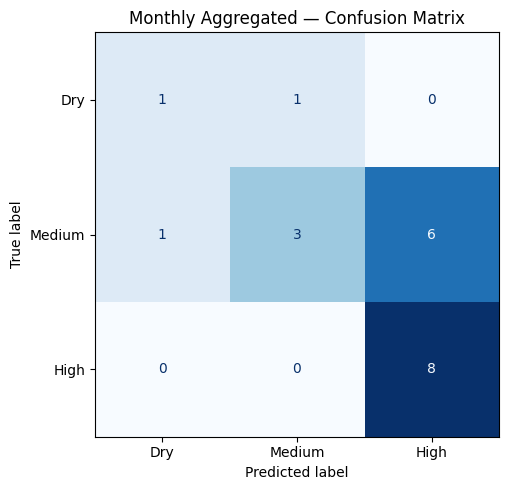

In [74]:

import calendar

# ── Rebuild daily predictions with dates for test set ─────────────────────────
test_keys_list = [k for k in field_data.keys() if k in TEST_FIELD_YEARS]

all_test_dates, all_test_keys_pw = [], []
for key in test_keys_list:
    df         = field_data[key]
    pred_dates = df.index[LOOKBACK:]
    all_test_dates.extend(pred_dates)
    all_test_keys_pw.extend([key] * len(pred_dates))

all_test_dates   = np.array(all_test_dates)
all_test_keys_pw = np.array(all_test_keys_pw)

# ── Build daily dataframe ──────────────────────────────────────────────────────
daily_df = pd.DataFrame({
    'field_year' : all_test_keys_pw,
    'date'       : pd.to_datetime(all_test_dates),
    'true'       : y_test,
    'predicted'  : preds_test,
})

daily_df['month'] = daily_df['date'].dt.month
daily_df['year']  = daily_df['date'].dt.year

# ── Monthly average per field-year ─────────────────────────────────────────────
monthly_rows = []

for (key, year, month), grp in daily_df.groupby(['field_year', 'year', 'month']):

    n_days_available = len(grp)          # days with predictions in this month

    avg_true = grp['true'].sum()      / n_days_available
    avg_pred = grp['predicted'].sum() / n_days_available

    # ── Round to nearest class ─────────────────────────────────────────────────
    monthly_true = round(avg_true)
    monthly_pred = round(avg_pred)

    # ── Clamp to valid class range (0, 1, 2) ───────────────────────────────────
    monthly_true = max(0, min(2, monthly_true))
    monthly_pred = max(0, min(2, monthly_pred))

    monthly_rows.append({
        'field_year'      : key,
        'year'            : year,
        'month'           : calendar.month_abbr[month],
        'n_days'          : n_days_available,
        'avg_true'        : round(avg_true, 3),
        'avg_pred'        : round(avg_pred, 3),
        'monthly_true'    : monthly_true,
        'monthly_pred'    : monthly_pred,
        'true_label'      : label_map[monthly_true],
        'pred_label'      : label_map[monthly_pred],
    })

monthly_df = pd.DataFrame(monthly_rows)

# ── Print the monthly table ────────────────────────────────────────────────────
print('── Monthly Aggregated Predictions ────────────────────────────────────')
print(monthly_df[['field_year','month','n_days','avg_true','avg_pred',
                   'true_label','pred_label']].to_string(index=False))

# ── Confusion Matrix from monthly predictions ──────────────────────────────────
monthly_true_arr = monthly_df['monthly_true'].values
monthly_pred_arr = monthly_df['monthly_pred'].values

acc = accuracy_score(monthly_true_arr, monthly_pred_arr)
f1  = f1_score(monthly_true_arr, monthly_pred_arr, average='weighted',
               zero_division=0)

print(f'\n── Monthly Confusion Matrix ───────────────────────────────────────────')
print(f'Accuracy : {acc:.4f}')
print(f'F1 Score : {f1:.4f}  (weighted)')
print(f'\nClassification Report:')
print(classification_report(monthly_true_arr, monthly_pred_arr,
                             target_names=CLASS_NAMES, zero_division=0))

cm   = confusion_matrix(monthly_true_arr, monthly_pred_arr)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Dry', 'Medium', 'High'])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Monthly Aggregated — Confusion Matrix')
plt.tight_layout()
plt.show()

In [75]:
# ── BLOCK 9.5: Misclassified Days — Last Real Acquisition Before Each ──────────

# ── Rebuild prediction dates for test set ─────────────────────────────────────
test_keys_list  = [k for k in field_data.keys() if k in TEST_FIELD_YEARS]

test_dates  = []
test_keys_per_window = []

for key in test_keys_list:
    df         = field_data[key]
    pred_dates = df.index[LOOKBACK:]
    test_dates.extend(pred_dates)
    test_keys_per_window.extend([key] * len(pred_dates))

test_dates           = np.array(test_dates)
test_keys_per_window = np.array(test_keys_per_window)

# ── Find misclassified indices ─────────────────────────────────────────────────
misclassified_mask = (preds_test != y_test)
misc_dates         = test_dates[misclassified_mask]
misc_keys          = test_keys_per_window[misclassified_mask]
misc_true          = y_test[misclassified_mask]
misc_pred          = preds_test[misclassified_mask]

label_map = {0: 'Dry', 1: 'High', 2: 'High'}

# ── For each misclassified day, find last real S1 and S2 acquisition ───────────
rows = []

for date, key, true_label, pred_label in zip(misc_dates, misc_keys,
                                              misc_true,  misc_pred):

    # raw acquisition dates for this field-year
    s2_real = ndvi_df[ndvi_df['field_year'] == key]['date'].dt.normalize().unique()
    s1_real = s1_df  [s1_df  ['field_year'] == key]['date'].dt.normalize().unique()

    s2_real = pd.DatetimeIndex(s2_real)
    s1_real = pd.DatetimeIndex(s1_real)

    # last S2 on or before prediction date
    s2_before  = s2_real[s2_real <= date]
    last_s2    = s2_before.max() if len(s2_before) > 0 else pd.NaT
    days_s2    = (date - last_s2).days if pd.notna(last_s2) else None

    # last S1 on or before prediction date
    s1_before  = s1_real[s1_real <= date]
    last_s1    = s1_before.max() if len(s1_before) > 0 else pd.NaT
    days_s1    = (date - last_s1).days if pd.notna(last_s1) else None

    rows.append({
        'field_year'    : key,
        'pred_date'     : pd.Timestamp(date).date(),
        'true_label'    : label_map[true_label],
        'predicted'     : label_map[pred_label],
        'last_s2_date'  : last_s2.date() if pd.notna(last_s2) else None,
        'days_since_s2' : days_s2,
        'last_s1_date'  : last_s1.date() if pd.notna(last_s1) else None,
        'days_since_s1' : days_s1,
    })

misc_df = pd.DataFrame(rows)

# ── Print the list ─────────────────────────────────────────────────────────────
print(f'Total misclassified days: {len(misc_df)}\n')
print(misc_df.to_string(index=False))

# ── Summary stats ──────────────────────────────────────────────────────────────
print(f'\n── Misclassified Days — Acquisition Gap Summary ──────────────────')
print(f'Mean days since last S2 : {misc_df["days_since_s2"].mean():.1f}')
print(f'Mean days since last S1 : {misc_df["days_since_s1"].mean():.1f}')
print(f'Max  days since last S2 : {misc_df["days_since_s2"].max()}')
print(f'Max  days since last S1 : {misc_df["days_since_s1"].max()}')

# ── Breakdown by error type ────────────────────────────────────────────────────
print(f'\n── Breakdown by Error Type ───────────────────────────────────────')
print(misc_df.groupby(['true_label','predicted'])[['days_since_s2',
                                                    'days_since_s1']].mean().round(1))

Total misclassified days: 189

field_year  pred_date true_label predicted last_s2_date  days_since_s2 last_s1_date  days_since_s1
   11_2024 2024-05-16       High      High   2024-05-12            4.0   2024-05-14            2.0
   11_2024 2024-05-17       High      High   2024-05-17            0.0   2024-05-14            3.0
   11_2024 2024-07-28       High      High   2024-07-21            7.0   2024-07-25            3.0
   11_2024 2024-07-29       High      High   2024-07-21            8.0   2024-07-25            4.0
   11_2024 2024-07-30       High       Dry   2024-07-21            9.0   2024-07-25            5.0
   11_2024 2024-07-31       High       Dry   2024-07-31            0.0   2024-07-25            6.0
   14_2023 2023-04-28       High       Dry         None            NaN         None            NaN
   14_2023 2023-04-29       High       Dry         None            NaN         None            NaN
   14_2023 2023-04-30       High       Dry         None            NaN        

In [76]:
# ── BLOCK 9.5: Misclassified Days — Last Real Acquisition Before Each ──────────

test_keys_list       = [k for k in field_data.keys() if k in TEST_FIELD_YEARS]
test_dates           = []
test_keys_per_window = []

for key in test_keys_list:
    df         = field_data[key]
    pred_dates = df.index[LOOKBACK:]
    test_dates.extend(pred_dates)
    test_keys_per_window.extend([key] * len(pred_dates))

test_dates           = np.array(test_dates)
test_keys_per_window = np.array(test_keys_per_window)

# ── Build full daily df first so we can look up previous day's true label ──────
full_daily = pd.DataFrame({
    'field_year': test_keys_per_window,
    'date'      : pd.to_datetime(test_dates),
    'true'      : y_test,
})

misclassified_mask = (preds_test != y_test)
misc_dates         = test_dates[misclassified_mask]
misc_keys          = test_keys_per_window[misclassified_mask]
misc_true          = y_test[misclassified_mask]
misc_pred          = preds_test[misclassified_mask]

label_map = {0: 'Dry', 1: 'Medium', 2: 'High'}

rows = []

for date, key, true_label, pred_label in zip(misc_dates, misc_keys,
                                              misc_true,  misc_pred):

    # ── Last real S2 acquisition ───────────────────────────────────────────────
    s2_real   = ndvi_df[ndvi_df['field_year'] == key]['date'].dt.normalize().unique()
    s1_real   = s1_df  [s1_df  ['field_year'] == key]['date'].dt.normalize().unique()
    s2_real   = pd.DatetimeIndex(s2_real)
    s1_real   = pd.DatetimeIndex(s1_real)

    s2_before = s2_real[s2_real <= date]
    last_s2   = s2_before.max() if len(s2_before) > 0 else pd.NaT
    days_s2   = (date - last_s2).days if pd.notna(last_s2) else None

    s1_before = s1_real[s1_real <= date]
    last_s1   = s1_before.max() if len(s1_before) > 0 else pd.NaT
    days_s1   = (date - last_s1).days if pd.notna(last_s1) else None

    # ── NEW: look up previous day's true label ─────────────────────────────────
    prev_date = pd.Timestamp(date) - pd.Timedelta(days=1)
    prev_row  = full_daily[
        (full_daily['field_year'] == key) &
        (full_daily['date']       == prev_date)
    ]

    if len(prev_row) > 0:
        prev_true_raw   = prev_row['true'].values[0]
        prev_true_label = label_map[prev_true_raw]
    else:
        prev_true_raw   = None
        prev_true_label = 'N/A'   # first day of field-year, no previous day

    rows.append({
        'field_year'    : key,
        'pred_date'     : pd.Timestamp(date).date(),
        'prev_day_true' : prev_true_label,        # ← NEW
        'true_label'    : label_map[true_label],
        'predicted'     : label_map[pred_label],
        'last_s2_date'  : last_s2.date() if pd.notna(last_s2) else None,
        'days_since_s2' : days_s2,
        'last_s1_date'  : last_s1.date() if pd.notna(last_s1) else None,
        'days_since_s1' : days_s1,
    })

misc_df = pd.DataFrame(rows)


# ── Save misclassified days table to CSV ──────────────────────────────────────
misc_df.to_csv('misclassified_days.csv', index=False)
print('Saved to misclassified_days.csv')


print(f'Total misclassified days: {len(misc_df)}\n')
print(misc_df.to_string(index=False))

print(f'\n── Misclassified Days — Acquisition Gap Summary ──────────────────')
print(f'Mean days since last S2 : {misc_df["days_since_s2"].mean():.1f}')
print(f'Mean days since last S1 : {misc_df["days_since_s1"].mean():.1f}')
print(f'Max  days since last S2 : {misc_df["days_since_s2"].max()}')
print(f'Max  days since last S1 : {misc_df["days_since_s1"].max()}')

print(f'\n── Breakdown by Error Type ───────────────────────────────────────')
print(misc_df.groupby(['true_label', 'predicted'])[['days_since_s2',
                                                     'days_since_s1']].mean().round(1))

# ── NEW: previous day true label vs error type ─────────────────────────────────
print(f'\n── Previous Day True Label vs Error Type ─────────────────────────')
print(misc_df.groupby(['prev_day_true', 'true_label', 'predicted']).size()
             .reset_index(name='count').to_string(index=False))

Saved to misclassified_days.csv
Total misclassified days: 189

field_year  pred_date prev_day_true true_label predicted last_s2_date  days_since_s2 last_s1_date  days_since_s1
   11_2024 2024-05-16           N/A     Medium      High   2024-05-12            4.0   2024-05-14            2.0
   11_2024 2024-05-17        Medium     Medium      High   2024-05-17            0.0   2024-05-14            3.0
   11_2024 2024-07-28          High       High    Medium   2024-07-21            7.0   2024-07-25            3.0
   11_2024 2024-07-29          High       High    Medium   2024-07-21            8.0   2024-07-25            4.0
   11_2024 2024-07-30          High     Medium       Dry   2024-07-21            9.0   2024-07-25            5.0
   11_2024 2024-07-31        Medium     Medium       Dry   2024-07-31            0.0   2024-07-25            6.0
   14_2023 2023-04-28           Dry     Medium       Dry         None            NaN         None            NaN
   14_2023 2023-04-29        Medi

In [77]:
# See all S1 dates for problem fields
for key in ['9_2023', '14_2023']:
    dates = s1_df[s1_df['field_year'] == key]['date'].sort_values().unique()
    print(f'\n{key} S1 dates:')
    for d in dates:
        print(f'  {pd.Timestamp(d).date()}')


9_2023 S1 dates:
  2023-05-03
  2023-05-08
  2023-05-15
  2023-05-20
  2023-06-01
  2023-06-13
  2023-06-25
  2023-08-12
  2023-08-19
  2023-08-24
  2023-08-31

14_2023 S1 dates:
  2023-05-03
  2023-05-08
  2023-05-15
  2023-05-20
  2023-06-01
  2023-06-13
  2023-06-25
  2023-08-12
  2023-08-19
  2023-08-24
  2023-08-31



── TRAIN — Monthly Aggregated Predictions ──────────────────────
field_year month  n_days  avg_true  avg_pred true_label pred_label
   11_2021   May      13     0.000     0.000        Dry        Dry
   11_2021   Jun      30     0.567     0.567     Medium     Medium
   11_2021   Jul      31     0.581     0.581     Medium     Medium
   11_2022   May       6     1.167     1.167     Medium     Medium
   11_2022   Jun      30     1.800     1.800       High       High
   11_2022   Jul      31     2.000     2.000       High       High
   11_2023   Jun      23     1.565     1.565       High       High
   11_2023   Jul      31     1.774     1.774       High       High
   12_2021   May      20     0.050     0.050        Dry        Dry
   12_2021   Jun      30     1.367     1.367     Medium     Medium
   12_2021   Jul      31     1.935     1.935       High       High
   12_2022   Jun      28     1.536     1.536       High       High
   12_2022   Jul      31     2.000     2.000       High       H

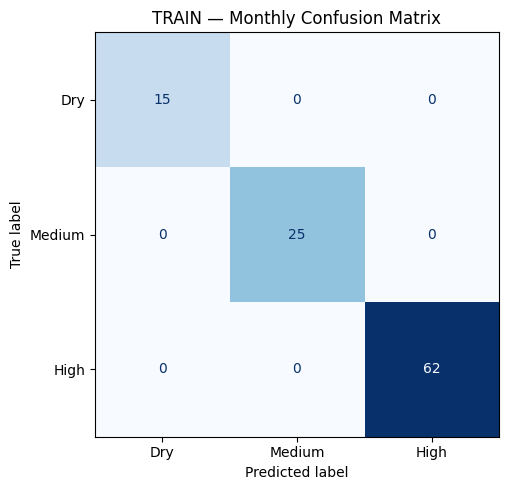


── VAL — Monthly Aggregated Predictions ──────────────────────
field_year month  n_days  avg_true  avg_pred true_label pred_label
    5_2024   May       8     0.375     0.250        Dry        Dry
    5_2024   Jun      30     1.767     1.933       High       High
    5_2024   Jul      31     1.806     2.000       High       High
   66_2021   Jun      14     0.643     1.214     Medium     Medium
   66_2021   Jul      31     0.581     1.484     Medium     Medium
   66_2023   Jun      25     1.640     1.760       High       High
   66_2023   Jul      31     1.258     1.968     Medium       High
    7_2022   Jul      20     2.000     2.000       High       High
    7_2023   Jun      12     2.000     2.000       High       High
    7_2023   Jul      31     2.000     1.903       High       High
    7_2024   Jun       7     2.000     2.000       High       High
    7_2024   Jul      31     2.000     2.000       High       High
    8_2023   Jun       9     2.000     2.000       High       Hig

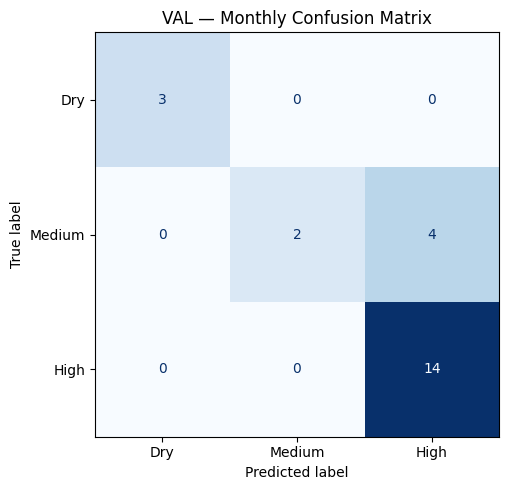


── TEST — Monthly Aggregated Predictions ──────────────────────
field_year month  n_days  avg_true  avg_pred true_label pred_label
   11_2024   May      16     1.875     2.000       High       High
   11_2024   Jun      30     2.000     2.000       High       High
   11_2024   Jul      31     1.935     1.806       High       High
   14_2023   Apr       4     0.750     0.000     Medium        Dry
   14_2023   May      31     0.065     0.000        Dry        Dry
   14_2023   Jun      30     1.000     2.000     Medium       High
   14_2023   Jul      31     0.645     2.000     Medium       High
    2_2024   Jun       9     1.778     2.000       High       High
    2_2024   Jul      23     1.565     2.000       High       High
   55_2021   Jun      14     0.643     0.929     Medium     Medium
   55_2021   Jul      31     0.677     1.613     Medium       High
    5_2022   May       5     1.000     1.000     Medium     Medium
    5_2022   Jun      30     1.933     1.867       High       Hi

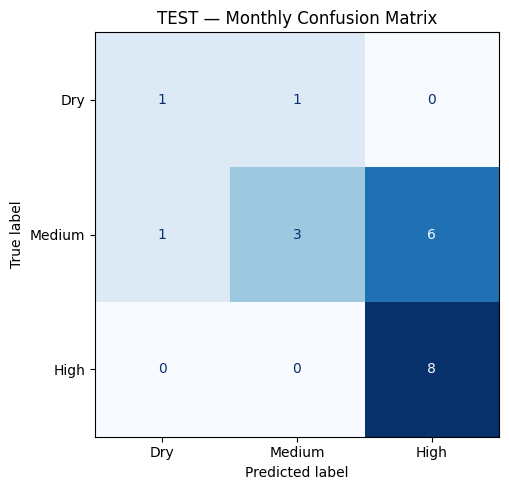

In [78]:
# ── BLOCK 9.6: Monthly Average Predictions → Confusion Matrix ─────────────────
import calendar

label_map = {0: 'Dry', 1: 'Medium', 2: 'High'}

def build_daily_df(keys_list, field_data, LOOKBACK, y_true, y_pred):
    """
    Rebuilds a daily dataframe with dates, true labels and predictions
    for a given set of field-year keys.
    """
    all_dates, all_keys_pw = [], []
    for key in keys_list:
        df         = field_data[key]
        pred_dates = df.index[LOOKBACK:]
        all_dates.extend(pred_dates)
        all_keys_pw.extend([key] * len(pred_dates))

    daily_df = pd.DataFrame({
        'field_year': np.array(all_keys_pw),
        'date'      : pd.to_datetime(all_dates),
        'true'      : y_true,
        'predicted' : y_pred,
    })
    daily_df['month'] = daily_df['date'].dt.month
    daily_df['year']  = daily_df['date'].dt.year
    return daily_df


def monthly_confusion(daily_df, title):
    """
    Takes a daily dataframe, aggregates to monthly class,
    prints results and plots confusion matrix.
    """
    monthly_rows = []

    for (key, year, month), grp in daily_df.groupby(['field_year', 'year', 'month']):

        n_days_available = len(grp)

        avg_true = grp['true'].sum()      / n_days_available
        avg_pred = grp['predicted'].sum() / n_days_available

        monthly_true = max(0, min(2, round(avg_true)))
        monthly_pred = max(0, min(2, round(avg_pred)))

        monthly_rows.append({
            'field_year'  : key,
            'year'        : year,
            'month'       : calendar.month_abbr[month],
            'n_days'      : n_days_available,
            'avg_true'    : round(avg_true, 3),
            'avg_pred'    : round(avg_pred, 3),
            'monthly_true': monthly_true,
            'monthly_pred': monthly_pred,
            'true_label'  : label_map[monthly_true],
            'pred_label'  : label_map[monthly_pred],
        })

    monthly_df = pd.DataFrame(monthly_rows)

    print(f'\n── {title} — Monthly Aggregated Predictions ──────────────────────')
    print(monthly_df[['field_year','month','n_days','avg_true','avg_pred',
                       'true_label','pred_label']].to_string(index=False))

    monthly_true_arr = monthly_df['monthly_true'].values
    monthly_pred_arr = monthly_df['monthly_pred'].values

    acc = accuracy_score(monthly_true_arr, monthly_pred_arr)
    f1  = f1_score(monthly_true_arr, monthly_pred_arr,
                   average='weighted', zero_division=0)

    print(f'\nAccuracy : {acc:.4f}')
    print(f'F1 Score : {f1:.4f}  (weighted)')
    print(f'\nClassification Report:')
    print(classification_report(monthly_true_arr, monthly_pred_arr,
                                 target_names=CLASS_NAMES, zero_division=0))

    cm   = confusion_matrix(monthly_true_arr, monthly_pred_arr)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Dry', 'Medium', 'High'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{title} — Monthly Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return monthly_df


# ── Build daily dfs for all three splits ──────────────────────────────────────
train_keys_list = [k for k in field_data.keys() if k in train_keys]
val_keys_list   = [k for k in field_data.keys() if k in val_keys]
test_keys_list  = [k for k in field_data.keys() if k in TEST_FIELD_YEARS]

daily_train = build_daily_df(train_keys_list, field_data, LOOKBACK, y_train, preds_train)
daily_val   = build_daily_df(val_keys_list,   field_data, LOOKBACK, y_val,   preds_val)
daily_test  = build_daily_df(test_keys_list,  field_data, LOOKBACK, y_test,  preds_test)

# ── Run monthly confusion for all three ───────────────────────────────────────
monthly_train = monthly_confusion(daily_train, 'TRAIN')
monthly_val   = monthly_confusion(daily_val,   'VAL')
monthly_test  = monthly_confusion(daily_test,  'TEST')

In [79]:
import joblib
joblib.dump(model,  'model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print('Model and scaler saved.')

Model and scaler saved.


In [80]:

import os

# Check where your notebook thinks it is
print(os.getcwd())

# List what's in the final folder
print(os.listdir('final'))

/orcd/data/dvaron/001/mkrishma/downscaling_ml
['sentinel2_2022_full - final - sentinel2_2022_full - Sheet1 (1).csv.csv', 'sentinel2_2024_full - final - sentinel2_2024_full - Sheet1 (1).csv (1).csv', 'all_daily_averages_2021.csv', 'sentinel2_2021_full - Sheet1 (1) - sentinel2_2021_full - Sheet1 (1).csv.csv', 'all_daily_averages_2023 (4).csv', '2024_sentinel_1 - Sheet1.csv', '2023_small_final - Sheet1 (1).csv', 'all_daily_averages_2024_final (2).csv', 'sentinel2_2023_full - Sheet1 (1).csv', 'all_daily_averages_2022 (4).csv', '2023_sentinel1 - Sheet1 (1).csv', 'Small_2021_final - Sheet1 (1).csv', 'sentinel2_2024_full - final - sentinel2_2024_full - Sheet1 (1).csv.csv', 'sentinel2_2022_full - Sheet1 (1).csv', 'small_2022_final - Sheet1 (2).csv', 'sentinel2_2024_full - Sheet1 (1).csv', 'all_daily_2021_averages_col22.csv', 'all_daily_averages_2023 (3).csv', '2021_sentinel_1 - Sheet1.csv', 'all_daily_averages_2024_final_col22.csv', 'sentinel2_2021_full - Sheet1 (1).csv', 'all_daily_2021_avera

In [7]:
import rasterio
import numpy as np
import pandas as pd

with rasterio.open('downscaling_files/rice_mask_imi_2024.tif') as src:
    arr = src.read(1)
    rows, cols = np.where(arr == 1)
    lon, lat = rasterio.transform.xy(src.transform, rows, cols)

# lon, lat are parallel arrays of every rice pixel center
rice_df = pd.DataFrame({
    'lat': lat,
    'lon': lon
})

print(f'Total rice pixels: {len(rice_df)}')
print(rice_df.head())

# save as CSV — same format as the GEE export would give you
#rice_df.to_csv('rice_pixels_imi_bbox_2016.csv', index=False)


# convert to list of (lat, lon) tuples — exactly what the loop expects
rice_pixels = list(zip(rice_df['lat'], rice_df['lon']))

print(f'Loaded {len(rice_pixels)} rice pixels')

Total rice pixels: 553827
         lat       lon
0  4095660.0  759180.0
1  4095540.0  759060.0
2  4095540.0  759180.0
3  4095420.0  758940.0
4  4095420.0  759060.0
Loaded 553827 rice pixels


Bounds:       BoundingBox(left=499920.0, bottom=3318720.0, right=789480.0, top=4099200.0)
CRS:          EPSG:32615
Shape:        (6504, 2413)
Unique vals:  [0 1]
Rice pixels:  553,827


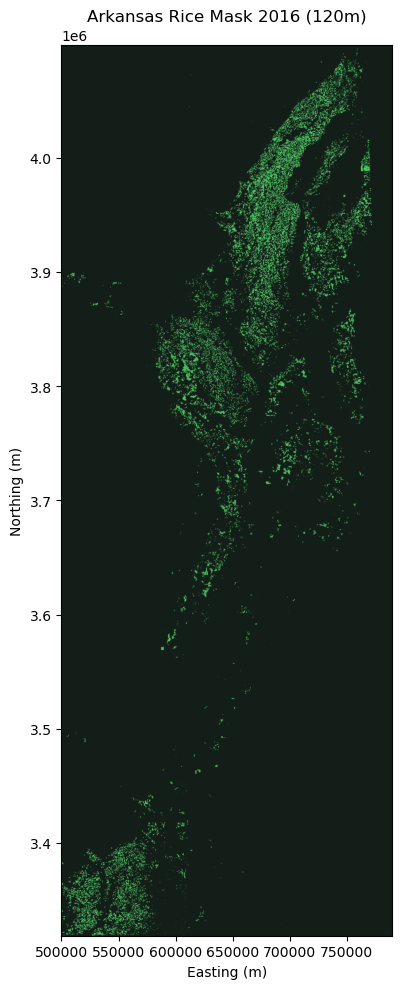

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open('downscaling_files/rice_mask_imi_2024.tif') as src:
    arr = src.read(1)
    bounds = src.bounds
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
    print(f'Bounds:       {bounds}')
    print(f'CRS:          {src.crs}')
    print(f'Shape:        {arr.shape}')
    print(f'Unique vals:  {np.unique(arr)}')
    print(f'Rice pixels:  {np.sum(arr == 1):,}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 10))

# Make rice pixels green, non-rice dark
rgb = np.zeros((*arr.shape, 3), dtype=np.uint8)
rgb[arr == 0] = [20, 30, 25]    # dark background
rgb[arr == 1] = [80, 200, 100]  # rice green

ax.imshow(rgb, extent=extent, origin='upper')
ax.set_title('Arkansas Rice Mask 2016 (120m)')
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')

plt.tight_layout()
plt.savefig('rice_mask_plot.png', dpi=150)
plt.show()

In [5]:
import rasterio
from rasterio.warp import transform_bounds
s=rasterio.open('downscaling_files/rice_mask_imi_2024.tif')
print(transform_bounds(s.crs,'EPSG:4326',*s.bounds))

(-93.00089957796807, 29.96523313350116, -89.74726505094883, 37.039010980609014)


In [6]:
from shapely.geometry import box
print(box(-93.00090, 29.96523, -89.74727, 37.03901).wkt)

POLYGON ((-89.74727 29.96523, -89.74727 37.03901, -93.0009 37.03901, -93.0009 29.96523, -89.74727 29.96523))


In [9]:
import subprocess
subprocess.run(['pip', 'install', 'pyproj'], check=True)

Defaulting to user installation because normal site-packages is not writeable


CompletedProcess(args=['pip', 'install', 'pyproj'], returncode=0)

In [10]:
import sys
!{sys.executable} -m pip install pyproj


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /home/mkrishma/.conda/envs/downscaling/bin/python -m pip install --upgrade pip


In [11]:
from pyproj import Transformer

transformer = Transformer.from_crs("EPSG:32615", "EPSG:4326", always_xy=True)
lon_deg, lat_deg = transformer.transform(
    rice_df['lon'].values,
    rice_df['lat'].values
)
rice_df['lat'] = lat_deg
rice_df['lon'] = lon_deg

print(rice_df[['lat','lon']].describe())
rice_df.to_csv('rice_pixels_imi_bbox_2016.csv', index=False)
# lat must show 33-37, lon must show -89 to -94


                 lat            lon
count  553827.000000  553827.000000
mean       34.369728     -91.235698
std         1.950792       0.732047
min        30.002807     -93.000220
25%        33.878621     -91.700597
50%        34.958634     -91.083294
75%        35.722341     -90.698994
max        36.989853     -89.999583


In [12]:
# Rebuild with correct coordinates
rice_pixels = list(zip(rice_df['lat'], rice_df['lon']))
print(f'Ready: {len(rice_pixels)} pixels')

Ready: 553827 pixels


In [13]:
import numpy as np
import os

os.makedirs('chunks', exist_ok=True)
chunks = np.array_split(rice_df, 10)
for i, chunk in enumerate(chunks):
    chunk.to_csv(f'chunks/chunk_{i}.csv', index=False)
    print(f'Chunk {i}: {len(chunk)} pixels saved')

Chunk 0: 55383 pixels saved


/home/mkrishma/.local/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Chunk 1: 55383 pixels saved
Chunk 2: 55383 pixels saved
Chunk 3: 55383 pixels saved
Chunk 4: 55383 pixels saved
Chunk 5: 55383 pixels saved
Chunk 6: 55383 pixels saved
Chunk 7: 55382 pixels saved
Chunk 8: 55382 pixels saved
Chunk 9: 55382 pixels saved


In [6]:
import ee
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

ee.Authenticate()
ee.Initialize(project='first-trial-483916')

# ── SECTION 2: Pull S2 time series for one rice pixel ────────────────────────
def pull_s2(lat, lon, start, end):
    point = ee.Geometry.Point([lon, lat])

    def extract(img):
        sample = img.sample(region=point, scale=30, numPixels=1).first()
        return sample.set({
            'date':           img.date().format('YYYY-MM-dd'),
            'solar_zenith':   img.get('MEAN_SOLAR_ZENITH_ANGLE'),
            'solar_azimuth':  img.get('MEAN_SOLAR_AZIMUTH_ANGLE'),
            'view_zenith_b4': img.get('MEAN_INCIDENCE_ZENITH_ANGLE_B4'),
            'view_azimuth_b4':img.get('MEAN_INCIDENCE_AZIMUTH_ANGLE_B4'),
            'view_zenith_b8': img.get('MEAN_INCIDENCE_ZENITH_ANGLE_B8'),
            'view_azimuth_b8':img.get('MEAN_INCIDENCE_AZIMUTH_ANGLE_B8'),
        })

    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterDate(start, end)
            .filterBounds(point)
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
            .select(['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12'])
            .map(extract))

    rows = []
    for f in s2.getInfo()['features']:
        p = f['properties']
        b8 = p.get('B8', np.nan);  b4 = p.get('B4', np.nan)
        b3 = p.get('B3', np.nan);  b11= p.get('B11', np.nan)
        rows.append({
            'date':            p.get('date'),
            'b2':  p.get('B2'), 'b3': b3,   'b4': b4,
            'b5':  p.get('B5'), 'b6': p.get('B6'), 'b7': p.get('B7'),
            'b8':  b8,          'b8a':p.get('B8A'),'b11':b11,
            'b12': p.get('B12'),
            'ndvi': (b8-b4)/(b8+b4+1e-8),
            'ndwi': (b3-b8)/(b3+b8+1e-8),
            'solar_zenith':    p.get('solar_zenith'),
            'solar_azimuth':   p.get('solar_azimuth'),
            'view_zenith_b4':  p.get('view_zenith_b4'),
            'view_azimuth_b4': p.get('view_azimuth_b4'),
            'view_zenith_b8':  p.get('view_zenith_b8'),
            'view_azimuth_b8': p.get('view_azimuth_b8'),
        })
    df = pd.DataFrame(rows)
    df['date'] = pd.to_datetime(df['date'])
    return df.set_index('date')


# ── SECTION 3: Pull S1 time series ───────────────────────────────────────────
def pull_s1(lat, lon, start, end):
    point = ee.Geometry.Point([lon, lat])

    def extract(img):
        sample = img.sample(region=point, scale=30, numPixels=1).first()
        return sample.set('date', img.date().format('YYYY-MM-dd'))

    s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterDate(start, end)
            .filterBounds(point)
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .select(['VV','VH'])
            .map(extract))

    rows = []
    for f in s1.getInfo()['features']:
        p  = f['properties']
        vv = p.get('VV', np.nan)
        vh = p.get('VH', np.nan)
        rows.append({
            'date': p.get('date'),
            'vv':   vv,
            'vh':   vh,
            'vv_vh_ratio_db':  vv - vh,
            'vv_vh_ratio_lin': 10**(vv/10) / (10**(vh/10) + 1e-8),
            'waterlike': 1 if (vv < -15 and vh < -20) else 0,
        })
    df = pd.DataFrame(rows)
    df['date'] = pd.to_datetime(df['date'])
    return df.set_index('date')


# ── SECTION 4: Build daily time series + 14-day windows ──────────────────────
S2_COLS = ['b2','b3','b4','b5','b6','b7','b8','b8a','b11','b12',
           'ndvi','ndwi','solar_zenith','solar_azimuth',
           'view_zenith_b4','view_azimuth_b4','view_zenith_b8','view_azimuth_b8']
S1_COLS = ['vv','vh','vv_vh_ratio_db','vv_vh_ratio_lin','waterlike']
INPUT_COLS = S2_COLS + S1_COLS   # 23 features total
LOOKBACK = 14

def build_windows(s2_df, s1_df):
     # ── FIX: remove duplicate dates, keep the first observation ───────────────
    s2_df = s2_df[~s2_df.index.duplicated(keep='first')]
    s1_df = s1_df[~s1_df.index.duplicated(keep='first')]
    # Build complete daily grid
    start = min(s2_df.index.min(), s1_df.index.min())
    end   = max(s2_df.index.max(), s1_df.index.max())
    daily = pd.date_range(start, end, freq='D')

    # Interpolate gaps (satellite doesn't observe every day)
    s2_daily = s2_df[S2_COLS].reindex(daily).interpolate('time').ffill().bfill()
    s1_daily = s1_df[S1_COLS].reindex(daily).interpolate('time').ffill().bfill()

    merged = pd.concat([s2_daily, s1_daily], axis=1).dropna()
    X_raw  = merged[INPUT_COLS].values.astype(np.float32)

    # Slide 14-day windows, flatten each → one row per day
    windows = []
    dates   = []
    for i in range(LOOKBACK, len(X_raw)):
        windows.append(X_raw[i-LOOKBACK:i].flatten())  # 14 × 23 = 322
        dates.append(merged.index[i])

    return np.array(windows), dates   # shape: (n_days, 322)

/home/mkrishma/.conda/envs/downscaling/lib/python3.10/site-packages/google/api_core/_python_version_support.py:273: FutureWarning: You are using a Python version (3.10.20) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [29]:
# ── Config ────────────────────────────────────────────────────────────────────
MONTH       = '2021-07'          # the IMI month
start       = '2021-06-17'       # 14 days before month start (need lookback!)
end         = '2021-07-31'       # end of your IMI month
LOOKBACK    = 14
INPUT_COLS  = S2_COLS + S1_COLS  # 23 features

# ── Predict for one pixel, summarize over the target month ───────────────────
def predict_pixel_month(lat, lon):
    s2 = pull_s2(lat, lon, start, end)   # pull slightly earlier for lookback
    s1 = pull_s1(lat, lon, start, end)

    X_windows, dates = build_windows(s2, s1)
    if len(X_windows) == 0:
        return None

    X_scaled = scaler.transform(X_windows)
    preds    = model.predict(X_scaled)        # 0/1/2 per day
    proba    = model.predict_proba(X_scaled)  # confidence per day

    df = pd.DataFrame({
        'date':           dates,
        'predicted_class': preds,
        'prob_dry':        proba[:,0],
        'prob_medium':     proba[:,1],
        'prob_high':       proba[:,2],
    })

    # ── Keep only days within the IMI month ───────────────────────────────────
    df = df[df['date'].dt.to_period('M') == MONTH]

    if len(df) == 0:
        return None

    # ── Summarize over the month ───────────────────────────────────────────────
    return {
        'lat':              lat,
        'lon':              lon,
        'dominant_class':   df['predicted_class'].mode()[0],     # most common class
        'dominant_label':   ['Dry','Medium','High'][int(df['predicted_class'].mode()[0])],
        'mean_class':       df['predicted_class'].mean(),        # 0-2 numeric avg
        'frac_dry':         (df['predicted_class'] == 0).mean(), # fraction of days dry
        'frac_medium':      (df['predicted_class'] == 1).mean(),
        'frac_high':        (df['predicted_class'] == 2).mean(),
        'avg_prob_dry':     df['prob_dry'].mean(),               # avg confidence
        'avg_prob_medium':  df['prob_medium'].mean(),
        'avg_prob_high':    df['prob_high'].mean(),
        'n_days':           len(df),
    }



In [30]:
from concurrent.futures import ThreadPoolExecutor
import time
import threading

# ── Thread-safe results list ───────────────────────────────────────────────────
results = []
results_lock = threading.Lock()
counter = {'n': 0}

def process_pixel(args):
    i, lat, lon = args
    try:
        time.sleep(0.3)  # avoid GEE rate limits
        row = predict_pixel_month(lat, lon)
        if row:
            row['lat'] = lat
            row['lon'] = lon
            with results_lock:
                results.append(row)
                counter['n'] += 1
                # ── Save checkpoint every 500 pixels ──────────────────────────
                if counter['n'] % 500 == 0:
                    pd.DataFrame(results).to_csv('results_checkpoint.csv', index=False)
                    print(f'Progress: {counter["n"]} pixels done')
    except Exception as e:
        print(f'Pixel {i} failed: {e}')

# ── Run 10 threads in parallel ─────────────────────────────────────────────────
with ThreadPoolExecutor(max_workers=10) as executor:
    executor.map(
        process_pixel,
        [(i, lat, lon) for i, (lat, lon) in enumerate(rice_pixels)]
    )

# ── Save final results ─────────────────────────────────────────────────────────
results_df = pd.DataFrame(results)
results_df.to_csv('rice_predictions.csv', index=False)
print(f'Done. {len(results_df)} pixels processed.')

Pixel 391 failed: Error in map(ID=20210727T164849_20210727T170247_T16SBF):
Element.set: Parameter 'object' is required and may not be null.
Progress: 500 pixels done
Pixel 870 failed: Error in map(ID=20210622T164901_20210622T165949_T15SYA):
Element.set: Parameter 'object' is required and may not be null.
Progress: 1000 pixels done
Progress: 1500 pixels done
Progress: 2000 pixels done
Progress: 2500 pixels done
Pixel 2746 failed: Error in map(ID=20210617T164839_20210617T170159_T16SBF):
Element.set: Parameter 'object' is required and may not be null.
Pixel 2929 failed: Error in map(ID=20210622T164901_20210622T165949_T15SYA):
Element.set: Parameter 'object' is required and may not be null.
Progress: 3000 pixels done
Pixel 3155 failed: Error in map(ID=20210617T164839_20210617T170159_T16SBF):
Element.set: Parameter 'object' is required and may not be null.
Progress: 3500 pixels done
Progress: 4000 pixels done
Progress: 4500 pixels done
Progress: 5000 pixels done
Pixel 5467 failed: Error in 

KeyboardInterrupt: 

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import rasterio

# ── Step 1: Load IMI NetCDF ───────────────────────────────────────────────────
imi = xr.open_dataset('downscaling_files/hemco_sa_diagnostics.2020_arkansas_annual_mean.nc')
print(imi)  # check variable names first

# Adjust 'XCH4' and coord names to match your actual NetCDF variables
# Common names: 'XCH4', 'CH4', 'emissions', 'flux'
# Common coord names: 'lat'/'lon' or 'latitude'/'longitude'

METHANE_VAR = 'EmisCH4_Rice'   # <-- change to match your file

# ── Step 2: Load your rice pixel predictions (from previous step) ─────────────
# results_df has columns: lat, lon, dominant_class (0/1/2), n_days, etc.
results_df = pd.read_csv('monthly_rice_predictions.csv')


with rasterio.open('SOC_pH_12km_grid_rice.tif') as src:
  soc_arr = src.read(1).astype(float)
  pH_arr = src.read(2).astype(float)
  nodata = src.nodata
  transform = src.transform
  height, width = soc_arr.shape


# ── Step 3: Assign each rice pixel to its nearest IMI 12km grid cell ──────────
imi_lats = imi.lat.values   # array of IMI cell center latitudes
imi_lons = imi.lon.values   # array of IMI cell center longitudes

def find_nearest(array, value):
    return array[np.argmin(np.abs(array - value))]

# Snap each rice pixel to nearest IMI cell center
results_df['imi_lat'] = results_df['lat'].apply(lambda x: find_nearest(imi_lats, x))
results_df['imi_lon'] = results_df['lon'].apply(lambda x: find_nearest(imi_lons, x))
results_df['imi_cell'] = results_df['imi_lat'].astype(str) + '_' + results_df['imi_lon'].astype(str)

# ── Step 4: Compute % area of each category per IMI cell ─────────────────────
def summarize_cell(group):
    n_total  = len(group)
    n_dry    = (group['dominant_class'] == 0).sum()
    n_medium = (group['dominant_class'] == 1).sum()
    n_high   = (group['dominant_class'] == 2).sum()
    return pd.Series({
        'n_rice_pixels': n_total,
        'pct_dry':       round(100 * n_dry* 900 / 144_000_000   , 2),
        'pct_medium':    round(100 * n_medium* 900/ 144_000_000, 2),
        'pct_high':      round(100 * n_high* 900 / 144_000_000, 2),
    })

cell_stats = (results_df
              .groupby(['imi_cell', 'imi_lat', 'imi_lon'])
              .apply(summarize_cell)
              .reset_index())

# ── Step 5: Attach methane value for each IMI cell ────────────────────────────
def get_methane(lat, lon):
    val = imi[METHANE_VAR].sel(lat=lat, lon=lon, method='nearest').values
    return float(val)

cell_stats['methane'] = cell_stats.apply(
    lambda r: get_methane(r['imi_lat'], r['imi_lon']), axis=1
)

# ── Step 6: Final table ───────────────────────────────────────────────────────
final_table = cell_stats[[
    'imi_cell', 'imi_lat', 'imi_lon',
    'methane',
    'n_rice_pixels',
    'pct_dry', 'pct_medium', 'pct_high'
]].sort_values('methane', ascending=False)

print(final_table.to_string(index=False))
final_table.to_csv('imi_methane_rice_category_table.csv', index=False)

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd

# ── Step 1: Connect to GEOS-FP OPeNDAP (no download needed) ──────────────────
# This streams directly from NASA's server
URL = 'https://opendap.nccs.nasa.gov/dods/GEOS-5/fp/0.25_deg/assim/tavg1_2d_slv_Nx'

print("Connecting to GEOS-FP server...")
geos = xr.open_dataset(URL, engine='netcdf4')
print(geos)   # check variable names — look for T2M

# ── Step 2: Subset to your region and time period ─────────────────────────────
# Your region from earlier: 31–38°N, 87–96°W
# Change date range to match your methane/rice data period

LAT_MIN, LAT_MAX =  33,  37
LON_MIN, LON_MAX = -93, -90
DATE_START = '2021-06-17'    # <-- change to your growing season start
DATE_END   = '2021-07-31'   # <-- change to your growing season end


print("Subsetting region and time...")
t2m_subset = geos['T2M'].sel(
    lat  = slice(LAT_MIN, LAT_MAX),
    lon  = slice(LON_MIN, LON_MAX),
    time = slice(DATE_START, DATE_END)
)

# ── Step 3: Average over time → one temperature value per grid cell ───────────
t2m_mean = t2m_subset.mean(dim='time') - 273.15   # Kelvin → Celsius
print(f"Temperature grid shape: {t2m_mean.shape}")
print(f"T2M range: {float(t2m_mean.min()):.1f} – {float(t2m_mean.max()):.1f} °C")

# ── Step 4: Load your final table and attach temperature ─────────────────────
df = pd.read_csv('imi_methane_rice_category_table.csv').dropna()

def get_temp(lat, lon):
    val = t2m_mean.sel(lat=lat, lon=lon, method='nearest').values
    return round(float(val), 2)

df['temp_c'] = df.apply(lambda r: get_temp(r['imi_lat'], r['imi_lon']), axis=1)

# ── Step 5: Save updated table ────────────────────────────────────────────────
final_table = df[[
    'imi_cell', 'imi_lat', 'imi_lon',
    'methane', 'temp_c', 'soc', 'ph',
    'n_rice_pixels',
    'pct_dry', 'pct_medium', 'pct_high'
]].sort_values('methane', ascending=False)

print(final_table.to_string(index=False))
final_table.to_csv('imi_methane_rice_category_table.csv', index=False)
print("Saved.")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('imi_methane_rice_category_table.csv').dropna()

feature_names = ['soc', 'ph', 'temp_c', 'pct_dry', 'pct_medium', 'pct_high', 'n_rice_pixels']

X = df[feature_names].values
y = df['methane'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 1. RIDGE  — penalises large coefficients but keeps all predictors
# ─────────────────────────────────────────────────────────────────────────────
ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge.fit(X_scaled, y)

print("── RIDGE ──────────────────────────────")
print(f"  Best alpha : {ridge.alpha_}")
print(f"  R²         : {r2_score(y, ridge.predict(X_scaled)):.3f}")
print(f"  RMSE       : {mean_squared_error(y, ridge.predict(X_scaled), squared=False):.3f}")
print(f"  Coefficients:")
feature_names = ['soc', 'ph', 'temp_c', 'pct_dry', 'pct_medium', 'pct_high', 'n_rice_pixels']

# then in each print block, replace zip(['methane','soc','ph'], ...) with:
for name, coef in zip(feature_names, ridge.coef_):   # or lasso.coef_ / enet.coef_
    print(f"    {name:15s}: {coef:.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# 2. LASSO  — zeroes out weak predictors (automatic feature selection)
# ─────────────────────────────────────────────────────────────────────────────
lasso = LassoCV(alphas=[0.001, 0.01, 0.1, 1, 10], cv=5, max_iter=10000)
lasso.fit(X_scaled, y)

print("\n── LASSO ──────────────────────────────")
print(f"  Best alpha : {lasso.alpha_}")
print(f"  R²         : {r2_score(y, lasso.predict(X_scaled)):.3f}")
print(f"  RMSE       : {mean_squared_error(y, lasso.predict(X_scaled), squared=False):.3f}")
print(f"  Coefficients (0 = predictor dropped):")
feature_names = ['soc', 'ph', 'temp_c', 'pct_dry', 'pct_medium', 'pct_high', 'n_rice_pixels']

# then in each print block, replace zip(['methane','soc','ph'], ...) with:
for name, coef in zip(feature_names, ridge.coef_):   # or lasso.coef_ / enet.coef_
    print(f"    {name:15s}: {coef:.4f}")

# ─────────────────────────────────────────────────────────────────────────────
# 3. ELASTIC NET  — mix of ridge + lasso, good when predictors are correlated
# ─────────────────────────────────────────────────────────────────────────────
enet = ElasticNetCV(
    alphas=[0.001, 0.01, 0.1, 1, 10],
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],   # 0=pure ridge, 1=pure lasso
    cv=5,
    max_iter=10000
)
enet.fit(X_scaled, y)

print("\n── ELASTIC NET ────────────────────────")
print(f"  Best alpha   : {enet.alpha_}")
print(f"  Best l1_ratio: {enet.l1_ratio_}  (0=ridge, 1=lasso)")
print(f"  R²           : {r2_score(y, enet.predict(X_scaled)):.3f}")
print(f"  RMSE         : {mean_squared_error(y, enet.predict(X_scaled), squared=False):.3f}")
print(f"  Coefficients:")
feature_names = ['soc', 'ph', 'temp_c', 'pct_dry', 'pct_medium', 'pct_high', 'n_rice_pixels']

# then in each print block, replace zip(['methane','soc','ph'], ...) with:
for name, coef in zip(feature_names, ridge.coef_):   # or lasso.coef_ / enet.coef_
    print(f"    {name:15s}: {coef:.4f}")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# ── Load your final table ─────────────────────────────────────────────────────
df = pd.read_csv('imi_methane_rice_category_table.csv').dropna()

feature_names = ['soc', 'ph', 'temp_c', 'pct_dry', 'pct_medium', 'pct_high', 'n_rice_pixels']

X = df[feature_names].values
y = df['methane'].values

# ── No scaling needed for BRT ─────────────────────────────────────────────────

# ─────────────────────────────────────────────────────────────────────────────
# 1. TUNE  — find best hyperparameters via cross-validation
# ─────────────────────────────────────────────────────────────────────────────
param_grid = {
    'n_estimators':   [100, 300, 500],   # number of trees
    'max_depth':      [2, 3, 4],         # keep shallow — you have few cells
    'learning_rate':  [0.01, 0.05, 0.1],
    'subsample':      [0.7, 1.0],        # fraction of rows per tree
}

brt = GradientBoostingRegressor(random_state=42)

search = GridSearchCV(
    brt,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
search.fit(X, y)

print("── BRT TUNING ─────────────────────────")
print(f"  Best params: {search.best_params_}")
print(f"  Best CV R² : {search.best_score_:.3f}")

# ─────────────────────────────────────────────────────────────────────────────
# 2. FIT  — refit with best params
# ─────────────────────────────────────────────────────────────────────────────
best_brt = search.best_estimator_   # already fitted on full data by GridSearchCV

y_pred = best_brt.predict(X)

print("\n── BRT PERFORMANCE ────────────────────")
print(f"  R²  (train): {r2_score(y, y_pred):.3f}")
print(f"  RMSE(train): {mean_squared_error(y, y_pred, squared=False):.3f}")

# Cross-validated R² is more honest for small datasets
cv_r2 = cross_val_score(best_brt, X, y, cv=5, scoring='r2')
print(f"  R²  (5-fold CV mean): {cv_r2.mean():.3f}  ± {cv_r2.std():.3f}")

# ─────────────────────────────────────────────────────────────────────────────
# 3. FEATURE IMPORTANCE  — which predictor drives methane most?
# ─────────────────────────────────────────────────────────────────────────────
importances = best_brt.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

print("\n── FEATURE IMPORTANCE ─────────────────")
for i in sorted_idx:
    bar = '█' * int(importances[i] * 40)
    print(f"  {feature_names[i]:15s}: {importances[i]:.3f}  {bar}")

# ─────────────────────────────────────────────────────────────────────────────
# 4. PLOT  — importance bar + predicted vs actual
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('BRT — methane prediction', fontsize=12)

# Feature importance
axes[0].barh(
    [feature_names[i] for i in sorted_idx[::-1]],
    importances[sorted_idx[::-1]],
    color='#378ADD', edgecolor='white', linewidth=0.5
)
axes[0].set_xlabel('Relative importance')
axes[0].set_title('Feature importance')

# Predicted vs actual
axes[1].scatter(y, y_pred, alpha=0.7, color='#378ADD', edgecolors='white', linewidth=0.5)
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
axes[1].plot(lims, lims, 'k--', linewidth=1, label='1:1 line')
axes[1].set_xlabel('Observed methane')
axes[1].set_ylabel('Predicted methane')
axes[1].set_title(f'Predicted vs observed  (R² = {r2_score(y, y_pred):.3f})')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('brt_methane.png', dpi=150, bbox_inches='tight')
plt.show()

Pixel 34448 failed: Error in map(ID=S1A_IW_GRDH_1SDV_20210718T235557_20210718T235622_038839_049544_548A):
Element.set: Parameter 'object' is required and may not be null.
Pixel 34449 failed: Error in map(ID=S1A_IW_GRDH_1SDV_20210730T235557_20210730T235622_039014_049A76_E4DD):
Element.set: Parameter 'object' is required and may not be null.
Progress: 34500 pixels done
Pixel 34580 failed: Error in map(ID=S1A_IW_GRDH_1SDV_20210718T235557_20210718T235622_038839_049544_548A):
Element.set: Parameter 'object' is required and may not be null.
Progress: 35000 pixels done
Progress: 35500 pixels done
Progress: 36000 pixels donePixel 36071 failed: Socket operation on non-socket
Pixel 36470 failed: Error in map(ID=S1A_IW_GRDH_1SDV_20210730T235557_20210730T235622_039014_049A76_E4DD):
Element.set: Parameter 'object' is required and may not be null.
Progress: 36500 pixels done
Pixel 36623 failed: Error in map(ID=S1A_IW_GRDH_1SDV_20210718T235557_20210718T235622_038839_049544_548A):
Element.set: Paramet